# Tasks for laboratory assignment 3

In [1]:
# imports section

import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.metrics import (r2_score, mean_squared_error, accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

IMAGES_DIR = 'images/assignment-3'
os.makedirs(IMAGES_DIR, exist_ok=True)

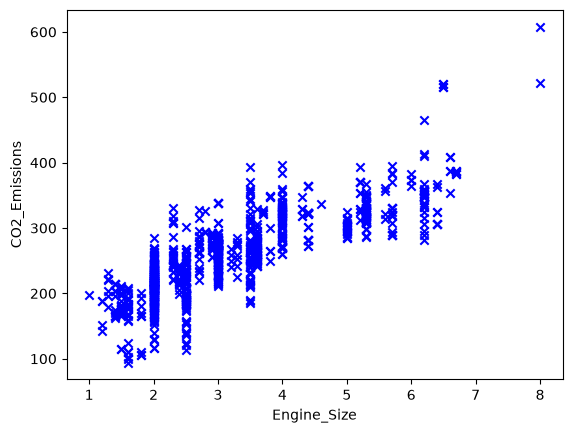

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        list: The list of texts as strings.
    """
    return pd.read_csv(file_path)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

In [4]:
def select_polynomial_degree(X, y, degrees=range(1, 6)):
    """Choose polynomial degree of the regression by 5-fold cross validated R^2."""
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = {}
    for d in degrees:
        model = make_pipeline(PolynomialFeatures(d, include_bias=False), LinearRegression())
        scores[d] = float(cross_val_score(model, X, y, cv=cv, scoring='r2').mean())
    print('Cross-validated R^2 by polynomial degree:', {d: round(s, 4) for d, s in scores.items()})
    # the simplest model that is within 0.025 of the best score:
    # high degrees gain very little and bend wildly at the edges of the data
    best = max(scores.values())
    return min(d for d, s in scores.items() if s >= best - 0.025)

def fit_regression(X, y, degree):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression())
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f'Validation: R^2 = {r2_score(y_test, pred):.4f}, RMSE = {np.sqrt(mean_squared_error(y_test, pred)):.4f}')
    model.fit(X, y)  # final model on all data
    reg = model[-1]
    theta = [float(reg.intercept_)] + [float(c) for c in reg.coef_]
    return model, theta

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Cross-validated R^2 by polynomial degree: {1: 0.6749, 2: 0.6795, 3: 0.6895, 4: 0.7002, 5: 0.6991}
Chosen polynomial degree: 2
Validation: R^2 = 0.6536, RMSE = 37.3532


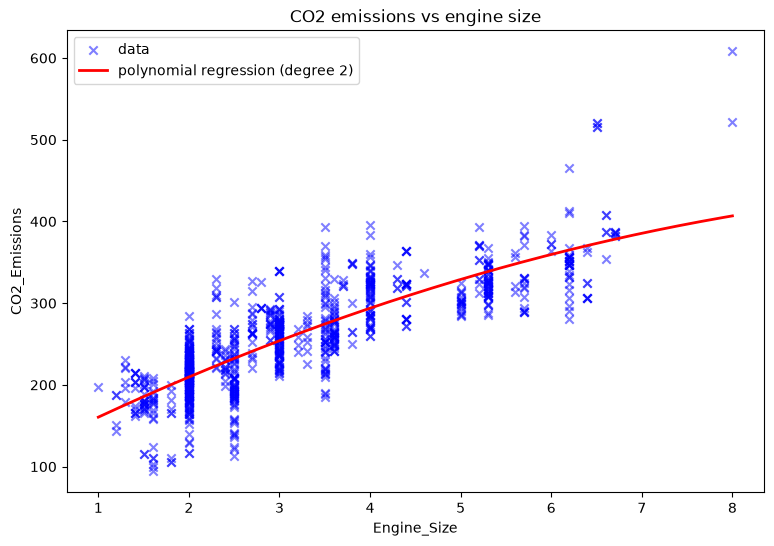

theta: [106.80347772377965, 56.025801806461075, -2.315381879015182]


[106.80347772377965, 56.025801806461075, -2.315381879015182]

In [5]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[['Engine_Size']].to_numpy()
    y = data['CO2_Emissions'].to_numpy()

    degree = select_polynomial_degree(X, y)
    print(f'Chosen polynomial degree: {degree}')
    model, theta = fit_regression(X, y, degree)

    grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
    plt.figure(figsize=(9, 6))
    plt.scatter(X, y, c='blue', marker='x', alpha=0.5, label='data')
    plt.plot(grid, model.predict(grid), c='red', lw=2, label=f'polynomial regression (degree {degree})')
    plt.xlabel('Engine_Size')
    plt.ylabel('CO2_Emissions')
    plt.title('CO2 emissions vs engine size')
    plt.legend()
    plt.savefig(f'{IMAGES_DIR}/co2_emissions.png', dpi=120)
    plt.show()
    print('theta:', theta)
    return theta

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Cross-validated R^2 by polynomial degree: {1: -0.2356, 2: 0.9093, 3: 0.9127, 4: 0.9152, 5: 0.9108}
Chosen polynomial degree: 2
Validation: R^2 = 0.8431, RMSE = 3.8573


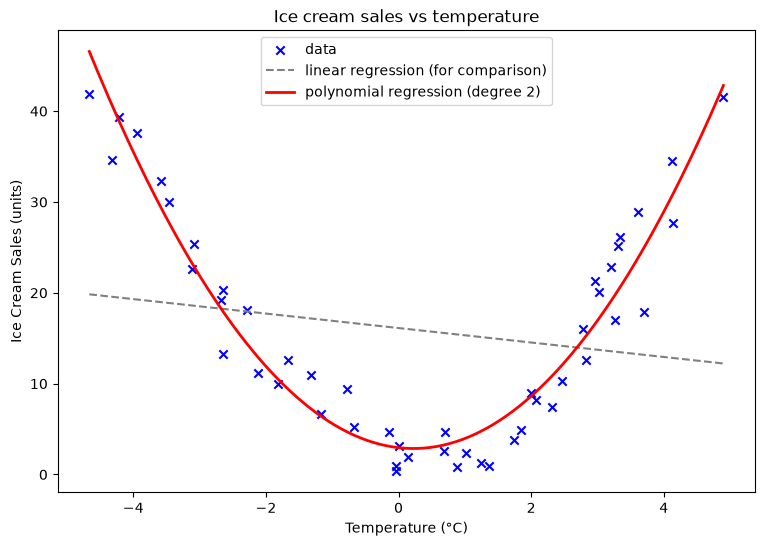

theta: [2.951774157993448, -0.8246816702106482, 1.829526229670208]


[2.951774157993448, -0.8246816702106482, 1.829526229670208]

In [6]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    X = data[['Temperature (°C)']].to_numpy()
    y = data['Ice Cream Sales (units)'].to_numpy()

    degree = select_polynomial_degree(X, y)
    print(f'Chosen polynomial degree: {degree}')
    model, theta = fit_regression(X, y, degree)

    grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
    linear = LinearRegression().fit(X, y)
    plt.figure(figsize=(9, 6))
    plt.scatter(X, y, c='blue', marker='x', label='data')
    plt.plot(grid, linear.predict(grid), c='gray', ls='--', label='linear regression (for comparison)')
    plt.plot(grid, model.predict(grid), c='red', lw=2, label=f'polynomial regression (degree {degree})')
    plt.xlabel('Temperature (°C)')
    plt.ylabel('Ice Cream Sales (units)')
    plt.title('Ice cream sales vs temperature')
    plt.legend()
    plt.savefig(f'{IMAGES_DIR}/ice_cream_sales.png', dpi=120)
    plt.show()
    print('theta:', theta)
    return theta

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

Cross-validated R^2 by polynomial degree: {1: 0.2451, 2: 0.2878, 3: 0.3007, 4: 0.3054}
Chosen polynomial degree: 2
Validation: R^2 = 0.2911, RMSE = 14379.2805


Gradient boosting (comparison): R^2 = 0.4185


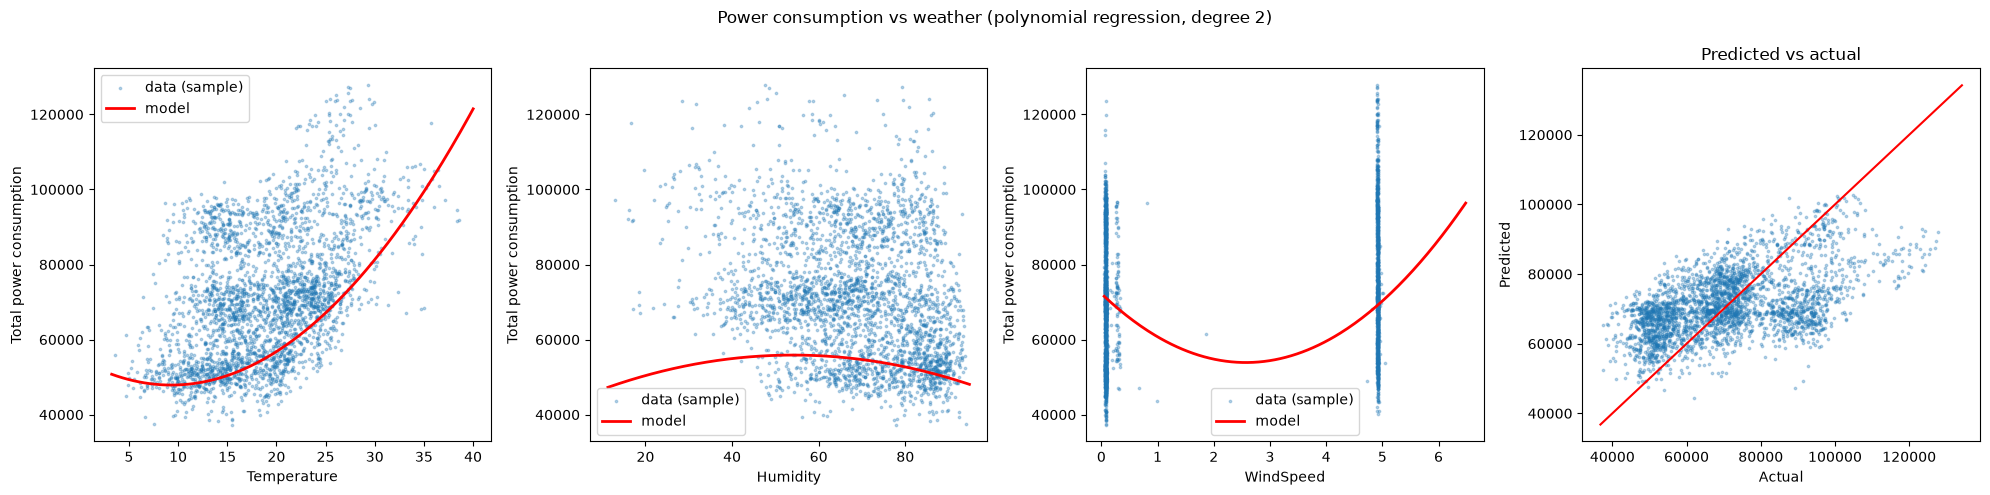

theta: [97180.0157, -3674.4008, 0.3569, -14065.2921, 78.1177, 29.936, 89.6357, -4.7051, -27.8284, 2776.584]


[97180.01567014332,
 -3674.4007961331085,
 0.35686064957924657,
 -14065.292130800564,
 78.11773664666623,
 29.935957462519625,
 89.63566636478464,
 -4.7050678339472185,
 -27.828369027178127,
 2776.5840408661234]

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor

def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed.
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    features = ['Temperature', 'Humidity', 'WindSpeed']
    X = data[features].to_numpy()
    # total consumption of the city = sum of the three zones
    y = data[['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']].sum(axis=1).to_numpy()

    degree = select_polynomial_degree(X, y, degrees=range(1, 5))
    print(f'Chosen polynomial degree: {degree}')
    model, theta = fit_regression(X, y, degree)

    # weather alone explains only a part of the consumption (time of day matters a lot),
    # a non-linear model is shown for comparison of what weather features can give at most
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    boosting = HistGradientBoostingRegressor(random_state=42).fit(X_train, y_train)
    print(f'Gradient boosting (comparison): R^2 = {r2_score(y_test, boosting.predict(X_test)):.4f}')

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    sample = np.random.default_rng(42).choice(len(X), 3000, replace=False)
    for ax, i, name in zip(axes, range(3), features):
        # effect of one feature while other features are fixed at their mean
        grid = np.tile(X.mean(axis=0), (200, 1))
        grid[:, i] = np.linspace(X[:, i].min(), X[:, i].max(), 200)
        ax.scatter(X[sample, i], y[sample], s=3, alpha=0.3, label='data (sample)')
        ax.plot(grid[:, i], model.predict(grid), c='red', lw=2, label='model')
        ax.set_xlabel(name)
        ax.set_ylabel('Total power consumption')
        ax.legend()
    pred = model.predict(X[sample])
    axes[3].scatter(y[sample], pred, s=3, alpha=0.3)
    axes[3].plot([y.min(), y.max()], [y.min(), y.max()], c='red')
    axes[3].set_xlabel('Actual')
    axes[3].set_ylabel('Predicted')
    axes[3].set_title('Predicted vs actual')
    fig.suptitle(f'Power consumption vs weather (polynomial regression, degree {degree})')
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/power_consumption.png', dpi=120)
    plt.show()
    print('theta:', np.round(theta, 4).tolist())
    return theta

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

Absolute correlation with target:
thall_2      0.566
thall_3      0.513
exng         0.450
oldpeak      0.448
thalachh     0.419
slp_2        0.418
slp_1        0.372
cp_2         0.341
caa_2        0.256
cp_1         0.253
sex          0.245
caa_1        0.216
age          0.211
caa_3        0.203
restecg_1    0.201
trtbps       0.151
thall_1      0.150
chol         0.150
cp_3         0.098
restecg_2    0.077
caa_4        0.054
fbs          0.035
Name: output, dtype: float64



Cross-validated accuracy (train data):
       RidgeClassifier, 22 features: 0.8549
    LogisticRegression, 22 features: 0.8508
    LogisticRegression, 12 features: 0.8425
         SGDClassifier, 12 features: 0.8384
         SGDClassifier, 22 features: 0.8383
       RidgeClassifier, 12 features: 0.8342
    LogisticRegression,  8 features: 0.7967
         SGDClassifier,  8 features: 0.7925
       RidgeClassifier,  8 features: 0.7884
    LogisticRegression,  5 features: 0.7844
         SGDClassifier,  5 features: 0.7760
       RidgeClassifier,  5 features: 0.7719

Chosen model: RidgeClassifier on 22 features: ['thall_2', 'thall_3', 'exng', 'oldpeak', 'thalachh', 'slp_2', 'slp_1', 'cp_2', 'caa_2', 'cp_1', 'sex', 'caa_1', 'age', 'caa_3', 'restecg_1', 'trtbps', 'thall_1', 'chol', 'cp_3', 'restecg_2', 'caa_4', 'fbs']

Validation accuracy: 0.8197, F1: 0.8451
              precision    recall  f1-score   support

    low risk       0.87      0.71      0.78        28
   high risk       0.79    

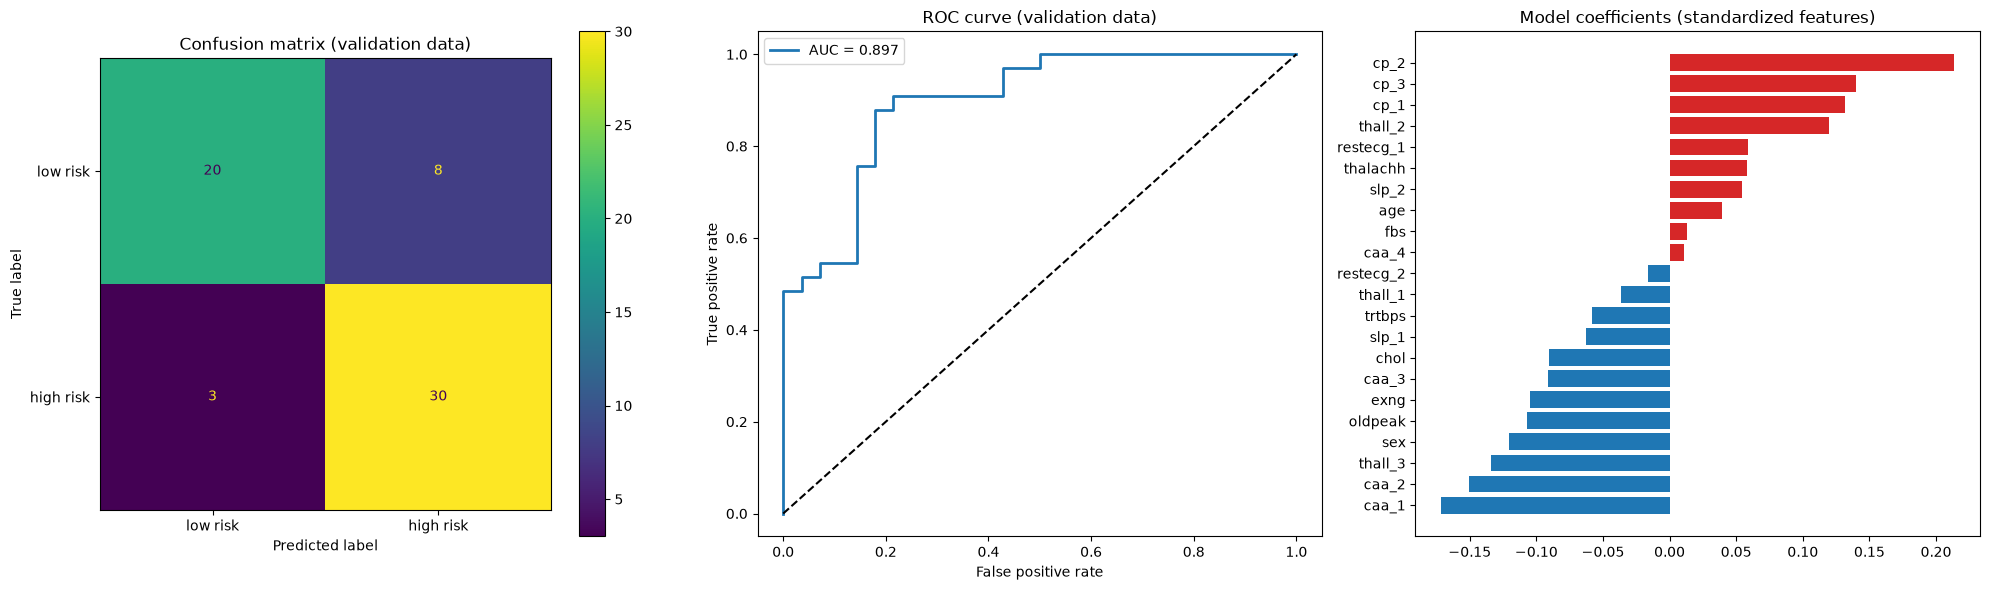

theta: [0.0871, 0.1194, -0.1341, -0.1048, -0.107, 0.0579, 0.0547, -0.0624, 0.2137, -0.1505, 0.1314, -0.1204, -0.1715, 0.0393, -0.0916, 0.0591, -0.0586, -0.0366, -0.0902, 0.1396, -0.0163, 0.0107, 0.0129]


[0.08713692946058084,
 0.11941237980691305,
 -0.134147052935537,
 -0.10475383482717458,
 -0.10703840541611755,
 0.05791900631103876,
 0.05468303879303764,
 -0.06240618851455931,
 0.2137309072973272,
 -0.15049830949879614,
 0.13137247583865244,
 -0.12035168189554868,
 -0.17146370385878498,
 0.0392700572981345,
 -0.09156421066800494,
 0.05909843663847039,
 -0.058587363806536015,
 -0.036633885706292904,
 -0.09022236666131582,
 0.13961028209604445,
 -0.016332933177624454,
 0.010733025193817271,
 0.012928181665323493]

In [8]:
def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    data = data.drop_duplicates()
    # categorical features are one-hot encoded, the others are scaled
    categorical = ['cp', 'restecg', 'slp', 'caa', 'thall']
    X = pd.get_dummies(data.drop(columns='output'), columns=categorical, drop_first=True, dtype=float)
    y = data['output']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # feature selection: correlation of each feature with the target on train data
    corr = pd.concat([X_train, y_train], axis=1).corr()['output'].drop('output').abs().sort_values(ascending=False)
    print('Absolute correlation with target:')
    print(corr.round(3))

    candidates = {
        'LogisticRegression': LogisticRegression(C=0.3, max_iter=1000),
        'RidgeClassifier': RidgeClassifier(alpha=10),
        'SGDClassifier': SGDClassifier(loss='log_loss', alpha=0.01, random_state=42),
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []
    for k in [5, 8, 12, len(corr)]:
        features = corr.index[:k].tolist()
        for name, clf in candidates.items():
            model = make_pipeline(StandardScaler(), clf)
            score = cross_val_score(model, X_train[features], y_train, cv=cv, scoring='accuracy').mean()
            results.append((score, -k, name, features))
    results.sort(key=lambda r: (r[0], r[1]), reverse=True)
    print('\nCross-validated accuracy (train data):')
    for score, k, name, _ in results:
        print(f'  {name:>20}, {-k:2d} features: {score:.4f}')

    best_score, _, best_name, features = results[0]
    print(f'\nChosen model: {best_name} on {len(features)} features: {features}')
    model = make_pipeline(StandardScaler(), candidates[best_name]).fit(X_train[features], y_train)

    pred = model.predict(X_test[features])
    print(f'\nValidation accuracy: {accuracy_score(y_test, pred):.4f}, F1: {f1_score(y_test, pred):.4f}')
    print(classification_report(y_test, pred, target_names=['low risk', 'high risk']))

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['low risk', 'high risk']).plot(ax=axes[0])
    axes[0].set_title('Confusion matrix (validation data)')

    scores = model.decision_function(X_test[features])
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y_test, scores):.3f}')
    axes[1].plot([0, 1], [0, 1], 'k--')
    axes[1].set_xlabel('False positive rate')
    axes[1].set_ylabel('True positive rate')
    axes[1].set_title('ROC curve (validation data)')
    axes[1].legend()

    clf = model[-1]
    coef = pd.Series(clf.coef_.ravel(), index=features).sort_values()
    axes[2].barh(coef.index, coef.values, color=np.where(coef.values > 0, 'tab:red', 'tab:blue'))
    axes[2].set_title('Model coefficients (standardized features)')
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/heart_classification.png', dpi=120)
    plt.show()

    theta = [float(clf.intercept_.ravel()[0])] + coef.reindex(features).astype(float).tolist()
    print('theta:', np.round(theta, 4).tolist())
    return theta

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

China GDP sigmoid: beta_1=716.354, beta_2=0.99720, validation R^2=0.9788


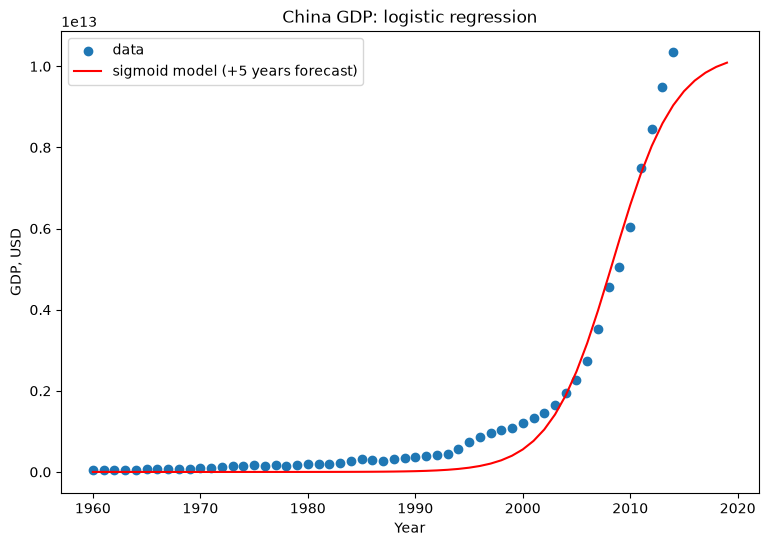

           Age   Edu  Years Employed  Income  Card Debt  Other Debt  \
cluster                                                               
0        41.76  1.60           13.62   60.08       1.51        3.27   
1        30.17  1.69            4.51   28.41       0.89        1.79   
2        41.08  2.24           15.73  114.65       6.35       10.73   

         DebtIncomeRatio  
cluster                   
0                   8.92  
1                   9.66  
2                  18.24  


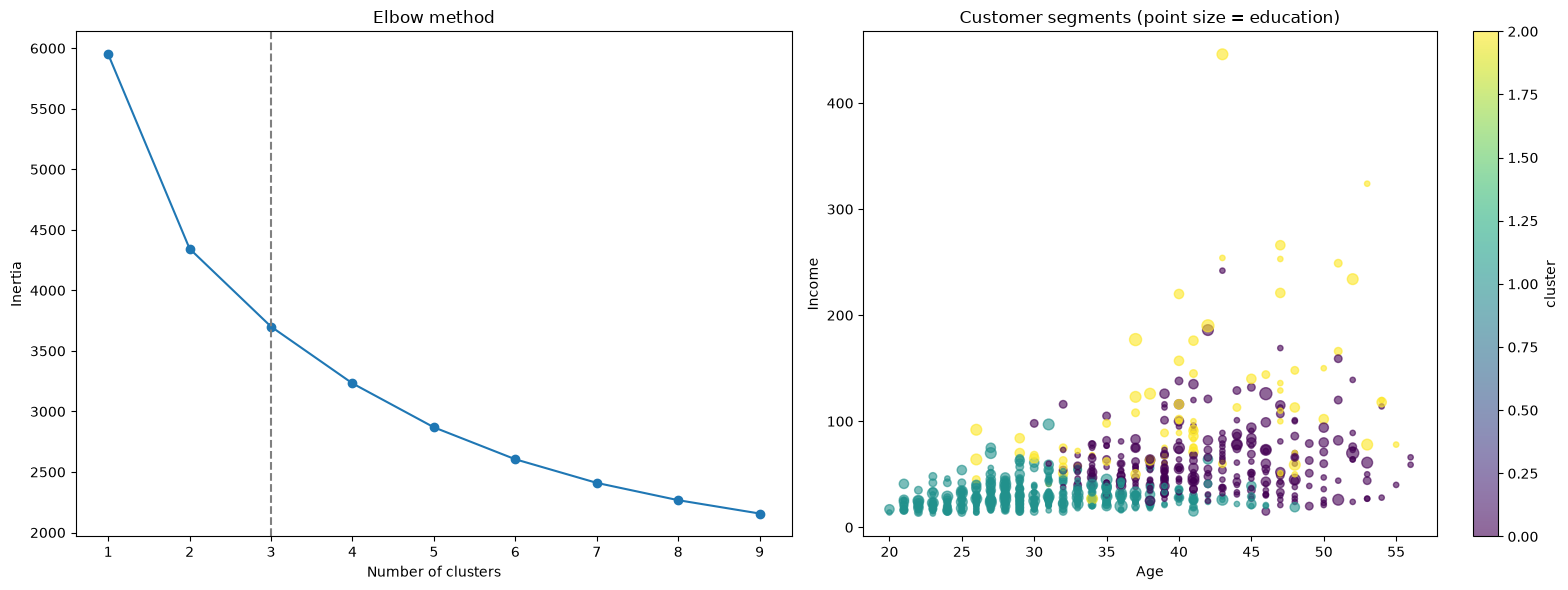

              precision    recall  f1-score   support

      benign       0.99      0.96      0.97        89
   malignant       0.92      0.98      0.95        48

    accuracy                           0.96       137
   macro avg       0.95      0.97      0.96       137
weighted avg       0.96      0.96      0.96       137



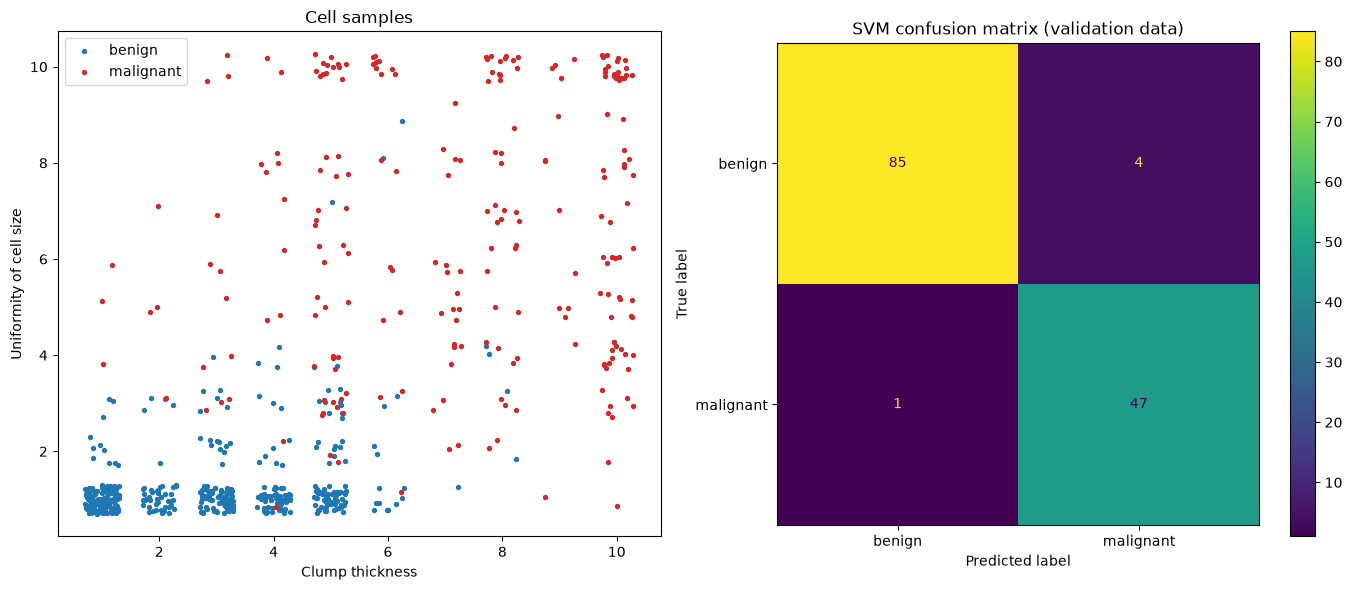

Prediction for a new sample [[8, 7, 8, 5, 6, 10, 7, 8, 2]] -> malignant


In [9]:
from scipy.optimize import curve_fit
from sklearn.cluster import KMeans
from sklearn.svm import SVC

def sigmoid(x, beta_1, beta_2):
    return 1 / (1 + np.exp(-beta_1 * (x - beta_2)))

def china_gdp(data):
    """Non-linear (logistic) regression of China's GDP growth."""
    x = data['Year'].to_numpy(dtype=float)
    y = data['Value'].to_numpy(dtype=float)
    x_n, y_n = x / x.max(), y / y.max()
    x_train, x_test, y_train, y_test = train_test_split(x_n, y_n, test_size=0.2, random_state=42)
    params, _ = curve_fit(sigmoid, x_train, y_train, p0=[500, 1])
    print(f'China GDP sigmoid: beta_1={params[0]:.3f}, beta_2={params[1]:.5f}, '
          f'validation R^2={r2_score(y_test, sigmoid(x_test, *params)):.4f}')
    params, _ = curve_fit(sigmoid, x_n, y_n, p0=params)

    future = np.arange(x.min(), x.max() + 6)
    plt.figure(figsize=(9, 6))
    plt.scatter(x, y, label='data')
    plt.plot(future, sigmoid(future / x.max(), *params) * y.max(), c='red', label='sigmoid model (+5 years forecast)')
    plt.xlabel('Year')
    plt.ylabel('GDP, USD')
    plt.title('China GDP: logistic regression')
    plt.legend()
    plt.savefig(f'{IMAGES_DIR}/china_gdp.png', dpi=120)
    plt.show()
    return params

def customer_segmentation(data):
    """K-means clustering of customers; the number of clusters is chosen with the elbow method."""
    features = ['Age', 'Edu', 'Years Employed', 'Income', 'Card Debt', 'Other Debt', 'DebtIncomeRatio']
    X = StandardScaler().fit_transform(data[features])
    inertia = [KMeans(k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 10)]
    k = 3
    labels = KMeans(k, n_init=10, random_state=42).fit_predict(X)
    data = data.assign(cluster=labels)
    print(data.groupby('cluster')[features].mean().round(2))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].plot(range(1, 10), inertia, 'o-')
    axes[0].axvline(k, ls='--', c='gray')
    axes[0].set_xlabel('Number of clusters')
    axes[0].set_ylabel('Inertia')
    axes[0].set_title('Elbow method')
    sc = axes[1].scatter(data['Age'], data['Income'], c=labels, s=data['Edu'] * 15, cmap='viridis', alpha=0.6)
    axes[1].set_xlabel('Age')
    axes[1].set_ylabel('Income')
    axes[1].set_title('Customer segments (point size = education)')
    fig.colorbar(sc, ax=axes[1], label='cluster')
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/customer_segmentation.png', dpi=120)
    plt.show()
    return labels

def cancer_cells(data):
    """SVM classification of benign (2) / malignant (4) cell samples."""
    data = data[pd.to_numeric(data['BareNuc'], errors='coerce').notna()].astype(int)
    X = data.drop(columns='Class')
    y = data['Class']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = SVC(kernel='rbf').fit(X_train, y_train)
    pred = model.predict(X_test)
    print(classification_report(y_test, pred, target_names=['benign', 'malignant']))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for cls, color, name in [(2, 'tab:blue', 'benign'), (4, 'tab:red', 'malignant')]:
        part = data[data['Class'] == cls]
        axes[0].scatter(part['Clump'] + np.random.uniform(-0.3, 0.3, len(part)),
                        part['UnifSize'] + np.random.uniform(-0.3, 0.3, len(part)), c=color, s=8, label=name)
    axes[0].set_xlabel('Clump thickness')
    axes[0].set_ylabel('Uniformity of cell size')
    axes[0].set_title('Cell samples')
    axes[0].legend()
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['benign', 'malignant']).plot(ax=axes[1])
    axes[1].set_title('SVM confusion matrix (validation data)')
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/cancer_cells.png', dpi=120)
    plt.show()

    new_sample = pd.DataFrame([[8, 7, 8, 5, 6, 10, 7, 8, 2]], columns=X.columns)
    print('Prediction for a new sample', new_sample.values.tolist(), '->',
          {2: 'benign', 4: 'malignant'}[model.predict(new_sample)[0]])
    return model

def additional(data):
    china_gdp(data)
    customer_segmentation(extract_texts_from_file('resources/cust_segmentation_Data.csv'))
    cancer_cells(extract_texts_from_file('resources/cell_samples.csv'))
    return None

data = extract_texts_from_file('resources/china_gdp.csv')
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



C:\Users\vladg\.venvs\ida\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Classifying text data...
Rating distribution:
Label
1     2469
2     2251
3     5071
4    18054
5    79173
Name: count, dtype: int64


LogisticRegression: accuracy=0.7268, macro F1=0.4656


LinearSVC: accuracy=0.7745, macro F1=0.4685

Classification report (LinearSVC):
              precision    recall  f1-score   support

           1       0.45      0.53      0.49       494
           2       0.24      0.22      0.23       450
           3       0.31      0.34      0.32      1014
           4       0.48      0.34      0.40      3611
           5       0.88      0.92      0.90     15835

    accuracy                           0.77     21404
   macro avg       0.47      0.47      0.47     21404
weighted avg       0.76      0.77      0.76     21404



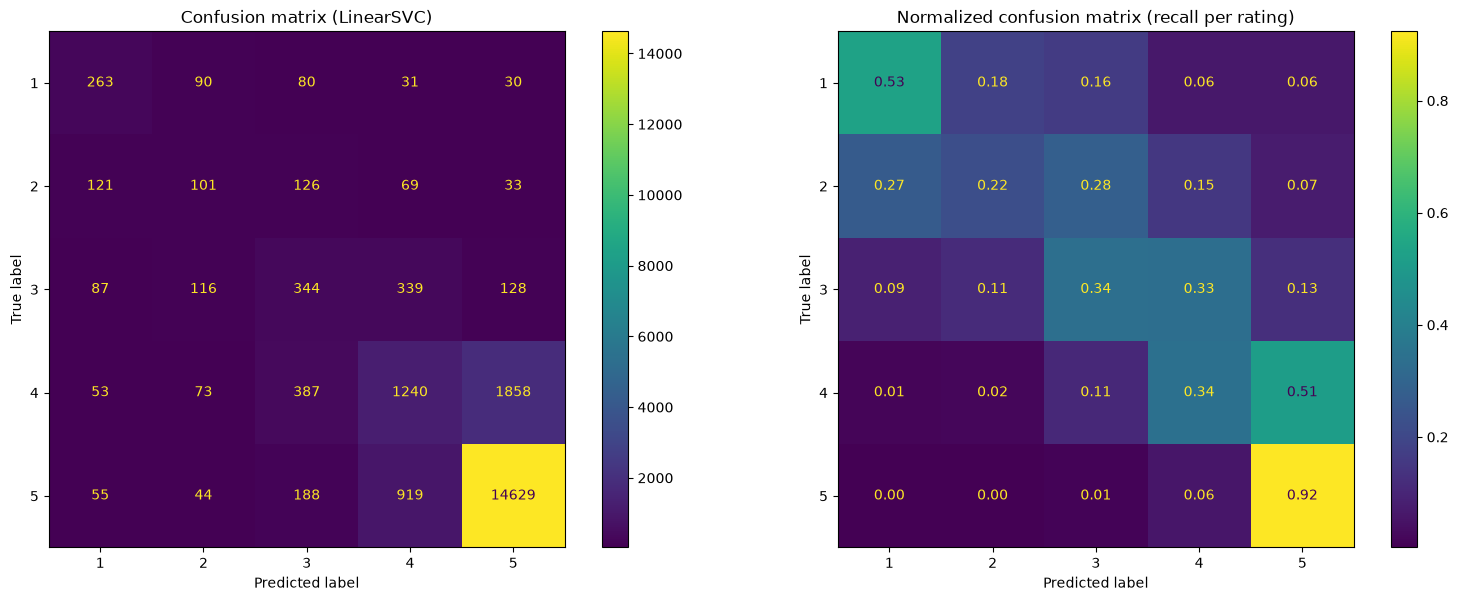

In [10]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues),
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    df = kagglehub.dataset_load(
            KaggleDatasetAdapter.PANDAS,
            url,
            csv_file
        )
    return df

def classify_text_ml(df):
    """
    Classify text data using a machine learning model.

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.

    Returns:
        None
    """
    print("Classifying text data...")
    df = df.dropna(subset=['Review', 'Label'])
    print('Rating distribution:')
    print(df['Label'].value_counts().sort_index())

    X_train, X_test, y_train, y_test = train_test_split(
        df['Review'], df['Label'], test_size=0.2, random_state=42, stratify=df['Label'])

    # word uni- and bigrams keep negations like "not good" as features
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)

    models = {
        'LogisticRegression': LogisticRegression(C=4, max_iter=2000, class_weight='balanced'),
        'LinearSVC': LinearSVC(C=0.3, class_weight='balanced'),
    }
    best_name, best_f1, best_pred = None, -1, None
    for name, model in models.items():
        pred = model.fit(X_train_vec, y_train).predict(X_test_vec)
        f1 = f1_score(y_test, pred, average='macro')
        print(f'{name}: accuracy={accuracy_score(y_test, pred):.4f}, macro F1={f1:.4f}')
        if f1 > best_f1:
            best_name, best_f1, best_pred = name, f1, pred

    print(f'\nClassification report ({best_name}):')
    print(classification_report(y_test, best_pred))

    labels = sorted(df['Label'].unique())
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred, labels=labels), display_labels=labels).plot(ax=axes[0])
    axes[0].set_title(f'Confusion matrix ({best_name})')
    ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred, labels=labels, normalize='true'),
                           display_labels=labels).plot(ax=axes[1], values_format='.2f')
    axes[1].set_title('Normalized confusion matrix (recall per rating)')
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/coursera_reviews_confusion.png', dpi=120)
    plt.show()

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
classify_text_ml(df)